<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 1: Vector and Matrix Operations for Deep Learning

**Category**: CO1 – Mathematical Foundations and Optimization  
**Objective**: Perform fundamental matrix transformations, similarity calculations, and manual forward-pass operations in NumPy.


### Task 1: Matrix Initialization and Shape Verification


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(101)

# Generate 6 customer profiles across 5 preference genres (scale 1 to 5)
user_profiles = np.random.uniform(1.0, 5.0, size=(6, 5)).round(2)
print("User Preference Matrix (6x5):\n", user_profiles)

# Generate 5 genre weightings across 4 catalog books
book_catalog = np.random.uniform(0.1, 1.0, size=(5, 4)).round(2)
print("\nBook Feature Matrix (5x4):\n", book_catalog)


User Preference Matrix (6x5):
 [[3.07 3.28 1.11 1.69 3.74]
 [4.34 2.23 4.57 3.89 1.76]
 [3.22 2.41 1.73 4.14 4.86]
 [1.93 1.33 3.41 3.92 2.1 ]
 [3.74 3.07 1.19 1.55 1.75]
 [4.98 3.08 3.32 3.94 3.17]]

Book Feature Matrix (5x4):
 [[0.92 0.83 0.46 0.42]
 [0.96 0.41 0.88 0.85]
 [0.58 0.93 0.19 0.19]
 [0.73 0.9  0.24 0.35]
 [0.71 0.25 0.73 0.54]]


### Task 2: Compute Matrix Product, Transpose, and Element-wise Transformations


In [2]:
# Dot product score matrix (6x5 @ 5x4 -> 6x4)
user_book_scores = np.matmul(user_profiles, book_catalog)
print("Computed Recommendation Affinity Matrix (6x4):\n", np.round(user_book_scores, 2))

# Matrix transpose and invertibility check
user_trans = user_profiles.T
print("\nTransposed User Matrix Shape:", user_trans.shape)

# Square submatrix determinant and inversion
sub_square = user_profiles[:5, :5]
det_val = np.linalg.det(sub_square)
print(f"Determinant of 5x5 submatrix: {det_val:.4f}")
if abs(det_val) > 1e-5:
    inv_mat = np.linalg.inv(sub_square)
    print("Inverse Matrix Shape:", inv_mat.shape)


Computed Recommendation Affinity Matrix (6x4):
 [[10.51  7.38  7.65  6.9 ]
 [12.87 12.71  7.05  6.9 ]
 [12.75 10.21  8.47  7.8 ]
 [ 9.38  9.37  5.18  5.1 ]
 [ 9.45  7.3   6.3   5.89]
 [14.59 12.82  8.89  8.43]]

Transposed User Matrix Shape: (5, 6)
Determinant of 5x5 submatrix: -55.0206
Inverse Matrix Shape: (5, 5)


### Task 3: Calculate Cosine Similarities Between Customers


In [3]:
# Pure NumPy Vectorized Cosine Similarity
norms = np.linalg.norm(user_profiles, axis=1, keepdims=True)
normalized_users = user_profiles / norms
cosine_sim_matrix = np.matmul(normalized_users, normalized_users.T)

print("Pairwise User Cosine Similarity Matrix:\n", np.round(cosine_sim_matrix, 3))

# Identify top similar distinct pair
np.fill_diagonal(cosine_sim_matrix, -1.0)
idx_max = np.unravel_index(np.argmax(cosine_sim_matrix), cosine_sim_matrix.shape)
print(f"\nMost Similar User Pair: User {idx_max[0]} and User {idx_max[1]} (Similarity: {cosine_sim_matrix[idx_max]:.4f})")


Pairwise User Cosine Similarity Matrix:
 [[1.    0.792 0.937 0.76  0.941 0.914]
 [0.792 1.    0.845 0.952 0.862 0.967]
 [0.937 0.845 1.    0.888 0.855 0.935]
 [0.76  0.952 0.888 1.    0.751 0.922]
 [0.941 0.862 0.855 0.751 1.    0.943]
 [0.914 0.967 0.935 0.922 0.943 1.   ]]

Most Similar User Pair: User 1 and User 5 (Similarity: 0.9667)


### Task 4: Dense Layer Forward Propagation Simulation


In [4]:
# Demonstrate dense layer equation: y = Wx + b
sample_user = user_profiles[0] # (5,)
weight_proj = np.random.normal(loc=0.0, scale=0.5, size=(4, 5)).round(3)
bias_vec = np.array([0.15, -0.20, 0.05, 0.10])

# Forward pass
layer_activation = np.dot(weight_proj, sample_user) + bias_vec
print("Input Vector x:", sample_user)
print("Weight Matrix W shape:", weight_proj.shape)
print("Output Vector y = Wx + b:", np.round(layer_activation, 3))


Input Vector x: [3.07 3.28 1.11 1.69 3.74]
Weight Matrix W shape: (4, 5)
Output Vector y = Wx + b: [1.278 2.585 1.921 3.546]


### Task 5: Visualize Score Matrix Heatmap


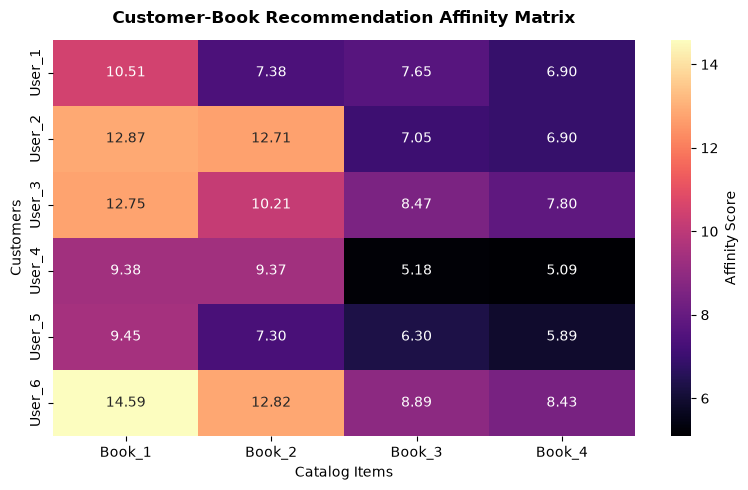

In [5]:
plt.figure(figsize=(8, 5))
sns.heatmap(user_book_scores, annot=True, fmt=".2f", cmap="magma",
            xticklabels=[f"Book_{k+1}" for k in range(4)],
            yticklabels=[f"User_{k+1}" for k in range(6)],
            cbar_kws={'label': 'Affinity Score'})
plt.title("Customer-Book Recommendation Affinity Matrix", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Catalog Items")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()
